# Un neurone artificiel codé à la main

J'ai suivi la formation Deep Learning de Machine Learnia sur YouTube, et voici ma version du premier
exercice : coder **un seul neurone** avec NumPy, sans TensorFlow ni PyTorch, pour savoir si une plante
est toxique à partir de deux mesures de ses feuilles.

L'intérêt n'est pas le problème lui-même (il est volontairement simple) mais de voir ce qui se passe
vraiment quand un réseau « apprend » : un calcul, une erreur, un gradient, une correction.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score

np.random.seed(0)   # pour retomber sur les mêmes résultats à chaque exécution
os.makedirs("figures", exist_ok=True)

## Les données

100 plantes, et pour chacune : $x_1$ la longueur des feuilles, $x_2$ leur largeur, et $y = 1$ si la
plante est toxique, $0$ sinon. On les génère avec `make_blobs` (deux nuages de points).

Petit détail qui a son importance : `y` sort de `make_blobs` avec la forme `(100,)`. Je le remets en
colonne `(100, 1)` pour que toutes les opérations matricielles qui suivent aient les bonnes dimensions.

X : (100, 2)  y : (100, 1)


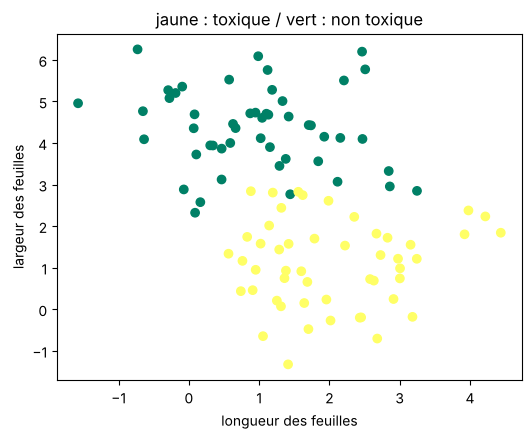

In [2]:
X, y = make_blobs(n_samples=100, n_features=2, centers=2, random_state=0)
y = y.reshape((y.shape[0], 1))
print("X :", X.shape, " y :", y.shape)

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="summer")
plt.xlabel("longueur des feuilles")
plt.ylabel("largeur des feuilles")
plt.title("jaune : toxique / vert : non toxique")
plt.show()

## Le modèle : un neurone

![neurone](https://raw.githubusercontent.com/nour395/neurone-artificiel-from-scratch/main/figures/architecture_neurone.png)

Le neurone fait deux choses :

1. une somme pondérée des entrées : $z = w_1 x_1 + w_2 x_2 + b$
2. il passe $z$ dans la **sigmoïde** $a = \dfrac{1}{1 + e^{-z}}$, qui renvoie un nombre entre 0 et 1.

On lit $a$ comme la probabilité que la plante soit toxique. Si $a \geq 0{,}5$ on répond « toxique ».

Pour traiter les 100 plantes d'un coup, on écrit tout avec des matrices : $X$ est de taille
$(100, 2)$, $W$ de taille $(2, 1)$, et $Z = X \cdot W + b$ donne directement une colonne de 100 valeurs.
C'est la **vectorisation**, et c'est ce qui permet de se passer de boucle sur les plantes.

In [3]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W, b)


def model(X, W, b):
    Z = X.dot(W) + b
    A = 1 / (1 + np.exp(-Z))
    return A

## La fonction coût : la Log Loss

Pour savoir si le neurone se trompe, on utilise la Log Loss :

$$\mathcal{L} = -\frac{1}{m}\sum_{i=1}^{m} \Big[ y_i \log(a_i) + (1-y_i)\log(1-a_i) \Big]$$

Pour une plante toxique ($y = 1$), il ne reste que $-\log(a)$ : si le neurone dit $a = 0{,}99$
l'erreur vaut $0{,}01$, s'il dit $a = 0{,}01$ elle vaut $4{,}6$. Un neurone sûr de lui **et** faux est
donc puni très fort. Cette fonction vient du maximum de vraisemblance (on suppose que $y$ suit une loi
de Bernoulli de paramètre $a$).

J'ajoute un minuscule `epsilon` dans les logarithmes pour ne jamais calculer $\log(0)$.

In [4]:
def log_loss(A, y):
    epsilon = 1e-15
    return 1 / len(y) * np.sum(-y * np.log(A + epsilon) - (1 - y) * np.log(1 - A + epsilon))

## Les gradients

Pour diminuer l'erreur, il faut savoir dans quel sens bouger $W$ et $b$. On dérive la Log Loss en
chaîne, $w \to z \to a \to \mathcal{L}$ :

$$\frac{\partial \mathcal{L}}{\partial w_1} = \frac{\partial \mathcal{L}}{\partial a}\cdot\frac{\partial a}{\partial z}\cdot\frac{\partial z}{\partial w_1}
= \frac{a-y}{a(1-a)} \cdot a(1-a) \cdot x_1 = (a - y)\,x_1$$

Le terme $a(1-a)$, qui est la dérivée de la sigmoïde, se simplifie : c'est ce qui rend le résultat
si propre. En moyennant sur toutes les plantes et en écrivant ça avec des matrices :

$$\frac{\partial \mathcal{L}}{\partial W} = \frac{1}{m} X^T (A - y) \qquad \frac{\partial \mathcal{L}}{\partial b} = \frac{1}{m}\sum (A - y)$$

In [5]:
def gradients(A, X, y):
    dW = 1 / len(y) * np.dot(X.T, A - y)
    db = 1 / len(y) * np.sum(A - y)
    return (dW, db)


def update(dW, db, W, b, learning_rate):
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)


def predict(X, W, b):
    A = model(X, W, b)
    return A >= 0.5

`update` fait la **descente de gradient** : on avance d'un petit pas dans le sens opposé au gradient,
$W \leftarrow W - \alpha \frac{\partial \mathcal{L}}{\partial W}$, avec un taux d'apprentissage $\alpha = 0{,}1$.

## L'apprentissage

On répète 100 fois : prédire, mesurer l'erreur, calculer les gradients, corriger. Je garde aussi
`W` et `b` à chaque étape pour pouvoir animer l'apprentissage à la fin.

précision finale : 0.9


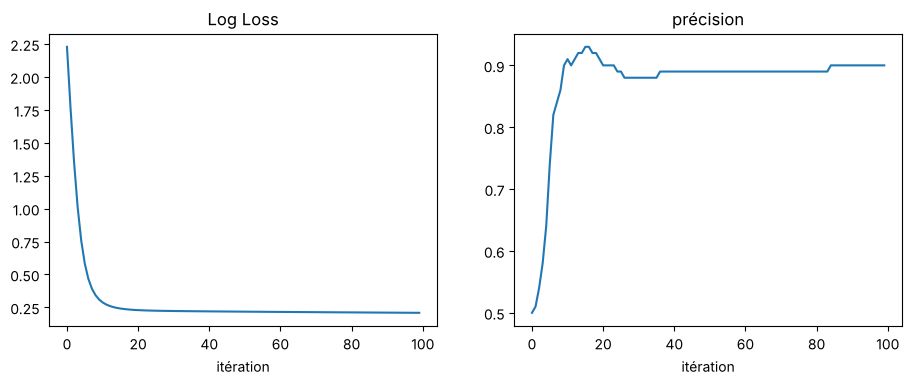

W = [ 1.36922046 -1.28217318]  b = [0.97098196]


In [6]:
def artificial_neuron(X, y, learning_rate=0.1, n_iter=100):
    W, b = initialisation(X)
    Loss, Acc, historique = [], [], []

    for i in range(n_iter):
        A = model(X, W, b)
        Loss.append(log_loss(A, y))
        Acc.append(accuracy_score(y, A >= 0.5))
        historique.append((W.copy(), b.copy()))
        dW, db = gradients(A, X, y)
        W, b = update(dW, db, W, b, learning_rate)

    print("précision finale :", accuracy_score(y, predict(X, W, b)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax1.plot(Loss); ax1.set_title("Log Loss"); ax1.set_xlabel("itération")
    ax2.plot(Acc); ax2.set_title("précision"); ax2.set_xlabel("itération")
    plt.show()
    return W, b, historique


W, b, historique = artificial_neuron(X, y)
print("W =", W.ravel(), " b =", b)

La Log Loss chute très vite pendant les 10 premières itérations puis continue à baisser doucement.
La précision, elle, bouge un peu (entre 88 et 93 %) avant de se poser à 90 % : elle ne compte que les
bonnes et mauvaises réponses, alors que la Log Loss tient aussi compte de la confiance du neurone.

## Une nouvelle plante

Une plante avec des feuilles de longueur 2 et de largeur 1 :

In [7]:
new_plant = np.array([2, 1])
print("probabilité d'être toxique :", model(new_plant, W, b))
print("toxique ?", predict(new_plant, W, b))

probabilité d'être toxique : [0.91888177]
toxique ? [ True]


## La frontière de décision

Le neurone hésite quand $a = 0{,}5$, c'est-à-dire quand $z = 0$ :
$w_1 x_1 + w_2 x_2 + b = 0$, soit $x_2 = \dfrac{-w_1 x_1 - b}{w_2}$. C'est une **droite**.

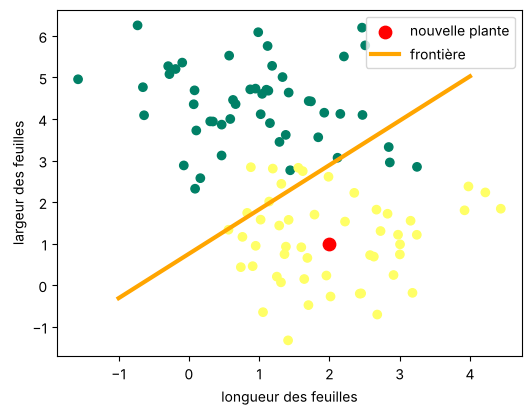

In [8]:
x0 = np.linspace(-1, 4, 100)
x1 = (-W[0] * x0 - b) / W[1]

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="summer")
plt.scatter(new_plant[0], new_plant[1], c="r", s=80, label="nouvelle plante")
plt.plot(x0, x1, c="orange", lw=3, label="frontière")
plt.xlabel("longueur des feuilles")
plt.ylabel("largeur des feuilles")
plt.legend()
plt.savefig("figures/frontiere_decision.png", dpi=150, bbox_inches="tight")
plt.show()

Et pour le plaisir, la frontière qui se met en place au fil des itérations (le GIF est enregistré
dans `figures/`) :

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="summer")
ligne, = ax.plot([], [], c="orange", lw=3)
titre = ax.set_title("")
ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)


def maj(i):
    Wi, bi = historique[i]
    ligne.set_data(x0, (-Wi[0] * x0 - bi) / Wi[1])
    titre.set_text(f"itération {i + 1}")
    return ligne, titre


anim = FuncAnimation(fig, maj, frames=range(0, len(historique), 2), interval=100)
anim.save("figures/apprentissage.gif", writer=PillowWriter(fps=10))
plt.close(fig)

## Bilan

Avec seulement trois paramètres ($w_1$, $w_2$ et $b$) appris par descente de gradient, le neurone
trouve une droite qui classe correctement 90 % des plantes. Tout le mécanisme d'un réseau de neurones
est déjà là : calcul de la sortie, mesure de l'erreur, gradients, mise à jour des poids.